# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


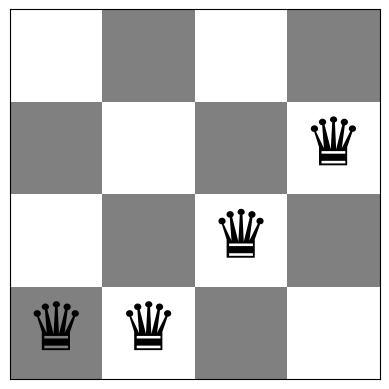

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


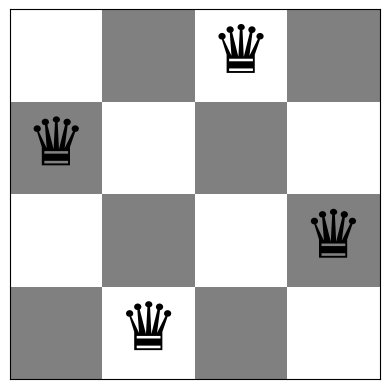

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [5]:
# Task 1: Steepest-ascend Hill Climbing Search
import time

def steepest_ascent_hc(board):
    """
    Steepest-Ascent Hill Climbing:
    Đánh giá toàn bộ các nước đi lân cận n x (n-1), chọn nước cải thiện tốt nhất.
    Dừng lại khi không có nước đi nào cải thiện (đạt cực tiểu cục bộ hoặc plateau).
    """
    t0 = time.perf_counter()
    n = len(board)
    current = list(board)
    curr_h = conflicts(current)
    steps = 0
    evals = 0
    history = [curr_h]
    
    while curr_h > 0:
        best_neighbor = None
        best_h = curr_h
        for col in range(n):
            orig_row = current[col]
            for row in range(n):
                if row == orig_row:
                    continue
                current[col] = row
                evals += 1
                h = conflicts(current)
                if h < best_h:
                    best_h = h
                    best_neighbor = (col, row)
            current[col] = orig_row
            
        if best_neighbor is None:
            # Không có láng giềng nào tốt hơn -> cực tiểu cục bộ
            break
            
        current[best_neighbor[0]] = best_neighbor[1]
        curr_h = best_h
        steps += 1
        history.append(curr_h)
        
    t1 = time.perf_counter()
    return current, curr_h, steps, evals, (t1 - t0), history

# Chạy thử nghiệm trên bàn cờ ngẫu nhiên kích thước n = 4 và n = 8
b4 = random_board(4)
sol4, h4, steps4, evals4, time4, _ = steepest_ascent_hc(b4)
print(f"=== Bàn cờ 4-Queens ===")
print(f"Ban đầu: {b4} (Xung đột = {conflicts(b4)})")
print(f"Kết quả: {sol4} (Xung đột = {h4}), Số bước = {steps4}, Số lần đánh giá = {evals4}, Thời gian = {time4*1000:.3f} ms")

b8 = random_board(8)
sol8, h8, steps8, evals8, time8, _ = steepest_ascent_hc(b8)
print(f"\n=== Bàn cờ 8-Queens ===")
print(f"Ban đầu: {b8} (Xung đột = {conflicts(b8)})")
print(f"Kết quả: {sol8} (Xung đột = {h8}), Số bước = {steps8}, Số lần đánh giá = {evals8}, Thời gian = {time8*1000:.3f} ms")

=== Bàn cờ 4-Queens ===
Ban đầu: [0 0 0 1] (Xung đột = 4)
Kết quả: [2, np.int32(0), 3, np.int32(1)] (Xung đột = 0), Số bước = 2, Số lần đánh giá = 24, Thời gian = 0.087 ms

=== Bàn cờ 8-Queens ===
Ban đầu: [7 1 7 1 2 6 3 6] (Xung đột = 5)
Kết quả: [4, np.int32(1), np.int32(7), 5, np.int32(2), 0, np.int32(3), np.int32(6)] (Xung đột = 1), Số bước = 3, Số lần đánh giá = 224, Thời gian = 1.029 ms


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
# Task 2: Inefficient Stochastic Hill Climbing
import random

def inefficient_stochastic_hc(board):
    """
    Inefficient Stochastic Hill Climbing:
    Duyệt toàn bộ n x (n-1) láng giềng, lọc ra tất cả các nước đi cải thiện (h < curr_h).
    Chọn ngẫu nhiên một nước đi trong số các nước đi cải thiện đó.
    Dừng lại khi không còn nước đi cải thiện nào.
    """
    t0 = time.perf_counter()
    n = len(board)
    current = list(board)
    curr_h = conflicts(current)
    steps = 0
    evals = 0
    history = [curr_h]
    
    while curr_h > 0:
        improving_moves = []
        for col in range(n):
            orig_row = current[col]
            for row in range(n):
                if row == orig_row:
                    continue
                current[col] = row
                evals += 1
                h = conflicts(current)
                if h < curr_h:
                    improving_moves.append(((col, row), h))
            current[col] = orig_row
            
        if not improving_moves:
            break
            
        move, new_h = random.choice(improving_moves)
        current[move[0]] = move[1]
        curr_h = new_h
        steps += 1
        history.append(curr_h)
        
    t1 = time.perf_counter()
    return current, curr_h, steps, evals, (t1 - t0), history

b8_test = random_board(8)
sol2, h2, steps2, evals2, time2, _ = inefficient_stochastic_hc(b8_test)
print(f"Inefficient Stochastic HC (8-Queens):")
print(f"Ban đầu: {b8_test} (h = {conflicts(b8_test)})")
print(f"Kết quả: {sol2} (h = {h2}), Số bước = {steps2}, Số lần đánh giá = {evals2}, Thời gian = {time2*1000:.3f} ms")

Inefficient Stochastic HC (8-Queens):
Ban đầu: [4 4 2 6 2 0 0 4] (h = 9)
Kết quả: [np.int32(4), 1, 3, np.int32(6), np.int32(2), 7, 5, 0] (h = 0), Số bước = 6, Số lần đánh giá = 336, Thời gian = 1.513 ms


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
# Task 3: Efficient Stochastic Hill Climbing (First-choice Hill Climbing)

def efficient_stochastic_hc(board, max_no_improve=None):
    """
    Efficient Stochastic Hill Climbing:
    Sinh lần lượt từng láng giềng ngẫu nhiên, nếu cải thiện (h < curr_h) thì chấp nhận ngay.
    Điều kiện dừng: Dừng nếu sau x lần thử liên tiếp không có nước đi nào cải thiện.
    
    Biện luận về giá trị x:
    Với bàn cờ kích thước n, tổng số trạng thái láng giềng là N = n * (n - 1).
    Xác suất một láng giềng cụ thể không được chọn trong x lần lấy mẫu ngẫu nhiên có hoàn lại là (1 - 1/N)^x.
    Để đảm bảo thử hầu như toàn bộ không gian láng giềng với xác suất tin cậy cao (>= 98-99%),
    ta chọn x xấp xỉ 4 * N = 4 * n * (n - 1).
    - Với n = 4 (N = 12): x = 50.
    - Với n = 8 (N = 56): x = 224 ~ 250.
    """
    t0 = time.perf_counter()
    n = len(board)
    if max_no_improve is None:
        max_no_improve = max(50, 4 * n * (n - 1))
        
    current = list(board)
    curr_h = conflicts(current)
    steps = 0
    evals = 0
    history = [curr_h]
    no_improve = 0
    
    while curr_h > 0 and no_improve < max_no_improve:
        col = random.randint(0, n - 1)
        orig_row = current[col]
        row = random.choice([r for r in range(n) if r != orig_row])
        current[col] = row
        evals += 1
        h = conflicts(current)
        if h < curr_h:
            curr_h = h
            steps += 1
            history.append(curr_h)
            no_improve = 0
        else:
            current[col] = orig_row
            no_improve += 1
            
    t1 = time.perf_counter()
    return current, curr_h, steps, evals, (t1 - t0), history

b8_eff = random_board(8)
sol3, h3, steps3, evals3, time3, _ = efficient_stochastic_hc(b8_eff)
print(f"Efficient Stochastic HC (8-Queens):")
print(f"Ban đầu: {b8_eff} (h = {conflicts(b8_eff)})")
print(f"Kết quả: {sol3} (h = {h3}), Số bước cải thiện = {steps3}, Số lần đánh giá = {evals3}, Thời gian = {time3*1000:.3f} ms")

Efficient Stochastic HC (8-Queens):
Ban đầu: [5 0 1 7 6 6 7 2] (h = 5)
Kết quả: [np.int32(5), 3, np.int32(1), np.int32(7), 4, np.int32(6), 0, np.int32(2)] (h = 0), Số bước cải thiện = 4, Số lần đánh giá = 78, Thời gian = 0.458 ms


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
# Task 4: Hill Climbing Search with Random Restarts

def random_restart_hc(algo_fn, n, max_restarts=100):
    """
    Random Restart: Khởi động lại thuật toán từ bàn cờ ngẫu nhiên mới nếu bị kẹt ở h > 0.
    Tối đa max_restarts lần thử.
    """
    t0 = time.perf_counter()
    total_steps = 0
    total_evals = 0
    best_h = float('inf')
    best_board = None
    restarts_used = 0
    
    for r in range(max_restarts):
        restarts_used = r + 1
        board = random_board(n)
        sol, h, steps, evals, _, _ = algo_fn(board)
        total_steps += steps
        total_evals += evals
        if h < best_h:
            best_h = h
            best_board = sol
        if best_h == 0:
            t1 = time.perf_counter()
            return best_board, best_h, restarts_used, total_steps, total_evals, (t1 - t0), True
            
    t1 = time.perf_counter()
    return best_board, best_h, restarts_used, total_steps, total_evals, (t1 - t0), (best_h == 0)

print("=== Thử nghiệm Random Restart (tối đa 100 lần) trên 8-Queens ===")
for name, fn in [('Steepest HC', steepest_ascent_hc), 
                 ('Inefficient Stochastic HC', inefficient_stochastic_hc), 
                 ('Efficient Stochastic HC', efficient_stochastic_hc)]:
    sol, h, restarts, total_st, total_ev, dur, succ = random_restart_hc(fn, 8, 100)
    print(f"[{name}] Thành công: {succ}, Restarts: {restarts}, Tổng xung đột = {h}, "
          f"Tổng bước = {total_st}, Tổng đánh giá = {total_ev}, Thời gian = {dur*1000:.2f} ms")

=== Thử nghiệm Random Restart (tối đa 100 lần) trên 8-Queens ===
[Steepest HC] Thành công: True, Restarts: 1, Tổng xung đột = 0, Tổng bước = 4, Tổng đánh giá = 224, Thời gian = 1.07 ms
[Inefficient Stochastic HC] Thành công: True, Restarts: 1, Tổng xung đột = 0, Tổng bước = 6, Tổng đánh giá = 336, Thời gian = 1.52 ms
[Efficient Stochastic HC] Thành công: True, Restarts: 3, Tổng xung đột = 0, Tổng bước = 14, Tổng đánh giá = 659, Thời gian = 3.34 ms


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

Simulated Annealing (Geometric): h = 1, Bước = 130, Thời gian = 8.90 ms
Simulated Annealing (Linear):    h = 0, Bước = 557, Thời gian = 3.51 ms


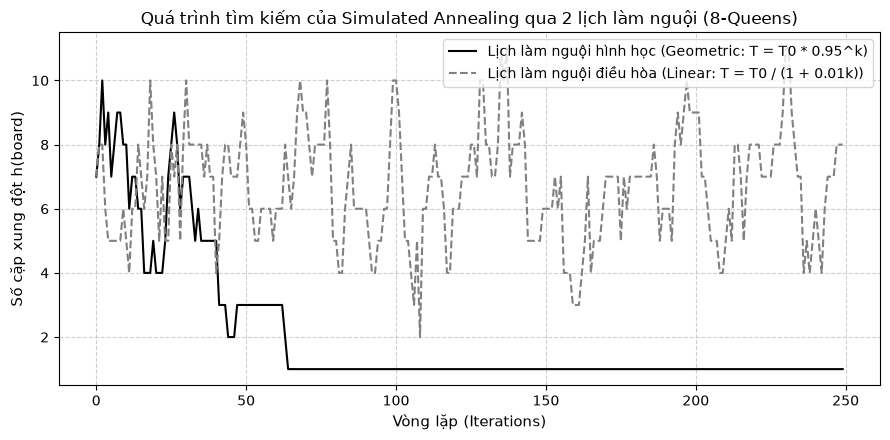

In [9]:
# Task 5: Simulated Annealing
import math

def simulated_annealing(board, schedule='geometric', T0=10.0, alpha=0.95, beta=0.01, max_steps=2000):
    """
    Simulated Annealing:
    Cho phép nhận nước đi tệ hơn (delta_h >= 0) với xác suất p = exp(-delta_h / T).
    Hỗ trợ 2 lịch làm nguội:
    - 'geometric': T = T * alpha (ví dụ alpha = 0.95)
    - 'linear':    T = T0 / (1 + beta * step) (làm nguội điều hòa / tuyến tính)
    """
    t0 = time.perf_counter()
    n = len(board)
    current = list(board)
    curr_h = conflicts(current)
    best_board = list(current)
    best_h = curr_h
    history = [curr_h]
    T = T0
    evals = 0
    steps = 0
    
    for step in range(1, max_steps + 1):
        if curr_h == 0:
            break
            
        col = random.randint(0, n - 1)
        orig_row = current[col]
        row = random.choice([r for r in range(n) if r != orig_row])
        current[col] = row
        evals += 1
        h = conflicts(current)
        dh = h - curr_h
        
        # Tiêu chuẩn Metropolis-Hastings
        if dh < 0 or (T > 1e-6 and random.random() < math.exp(-dh / T)):
            curr_h = h
            steps += 1
            if curr_h < best_h:
                best_h = curr_h
                best_board = list(current)
        else:
            current[col] = orig_row
            
        history.append(curr_h)
        
        if schedule == 'geometric':
            T = max(1e-4, T * alpha)
        elif schedule == 'linear':
            T = max(1e-4, T0 / (1 + beta * step))
            
    t1 = time.perf_counter()
    return best_board, best_h, steps, evals, (t1 - t0), history

# Chạy thử nghiệm và so sánh hai lịch làm nguội
test_b8 = random_board(8)
sol_geom, h_geom, st_g, ev_g, t_g, hist_geom = simulated_annealing(test_b8, schedule='geometric', T0=10.0, alpha=0.95)
sol_lin, h_lin, st_l, ev_l, t_l, hist_lin = simulated_annealing(test_b8, schedule='linear', T0=10.0, beta=0.01)

print(f"Simulated Annealing (Geometric): h = {h_geom}, Bước = {st_g}, Thời gian = {t_g*1000:.2f} ms")
print(f"Simulated Annealing (Linear):    h = {h_lin}, Bước = {st_l}, Thời gian = {t_l*1000:.2f} ms")

# Trực quan hóa quá trình tìm kiếm của 2 lịch làm nguội
plt.figure(figsize=(9, 4.5))
plt.plot(hist_geom[:250], label='Lịch làm nguội hình học (Geometric: T = T0 * 0.95^k)', color='black', linewidth=1.5)
plt.plot(hist_lin[:250], '--', label='Lịch làm nguội điều hòa (Linear: T = T0 / (1 + 0.01k))', color='gray', linewidth=1.5)
plt.xlabel('Vòng lặp (Iterations)', fontsize=11)
plt.ylabel('Số cặp xung đột h(board)', fontsize=11)
plt.title('Quá trình tìm kiếm của Simulated Annealing qua 2 lịch làm nguội (8-Queens)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [10]:
# Task 6: Algorithm Behavior Analysis - So sánh trên bàn cờ n = 4 và n = 8 (100 lượt chạy)
import pandas as pd

table_data = []
algorithms = [
    ('Steepest asc. HC', lambda b: steepest_ascent_hc(b)),
    ('Ineff. Stochastic HC', lambda b: inefficient_stochastic_hc(b)),
    ('Efficient Stochastic HC', lambda b: efficient_stochastic_hc(b)),
    ('Simulated Annealing', lambda b: simulated_annealing(b, schedule='geometric'))
]

NUM_TESTS = 100
for size in [4, 8]:
    for name, fn in algorithms:
        runtimes = []
        final_h = []
        optimal_cnt = 0
        
        for _ in range(NUM_TESTS):
            b = random_board(size)
            _, h, _, _, dur, _ = fn(b)
            runtimes.append(dur)
            final_h.append(h)
            if h == 0:
                optimal_cnt += 1
                
        table_data.append({
            'Algorithm': name,
            'Board size': size,
            'Avg. Run time (s)': f"{np.mean(runtimes):.6f}",
            'Avg. number of conflicts': f"{np.mean(final_h):.3f}",
            '% of runs ending in optimal solution': f"{(optimal_cnt / NUM_TESTS) * 100:.1f}%"
        })

df_task6 = pd.DataFrame(table_data)
print(df_task6.to_string(index=False))

              Algorithm  Board size Avg. Run time (s) Avg. number of conflicts % of runs ending in optimal solution
       Steepest asc. HC           4          0.000070                    0.570                                47.0%
   Ineff. Stochastic HC           4          0.000085                    0.740                                35.0%
Efficient Stochastic HC           4          0.000150                    0.870                                31.0%
    Simulated Annealing           4          0.000184                    0.000                               100.0%
       Steepest asc. HC           8          0.001040                    1.180                                16.0%
   Ineff. Stochastic HC           8          0.001358                    1.390                                14.0%
Efficient Stochastic HC           8          0.001362                    1.340                                10.0%
    Simulated Annealing           8          0.002927                   

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

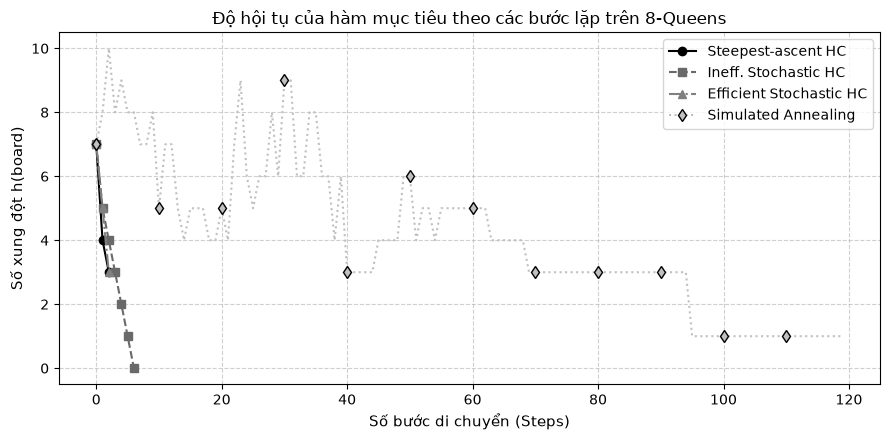

In [11]:
# Task 6: Algorithm Convergence Plot on 8-Queens
rep_b = random_board(8)
_, _, _, _, _, h_steepest = steepest_ascent_hc(list(rep_b))
_, _, _, _, _, h_ineff = inefficient_stochastic_hc(list(rep_b))
_, _, _, _, _, h_eff = efficient_stochastic_hc(list(rep_b))
_, _, _, _, _, h_sa = simulated_annealing(list(rep_b), schedule='geometric')

plt.figure(figsize=(9, 4.5))
plt.plot(h_steepest, 'o-', label='Steepest-ascent HC', color='black', markevery=max(1, len(h_steepest)//5))
plt.plot(h_ineff, 's--', label='Ineff. Stochastic HC', color='dimgray', markevery=max(1, len(h_ineff)//5))
plt.plot(h_eff, '^-.', label='Efficient Stochastic HC', color='gray', markevery=max(1, len(h_eff)//5))
plt.plot(h_sa[:120], 'd:', label='Simulated Annealing', color='silver', markevery=10, markeredgecolor='black')
plt.xlabel('Số bước di chuyển (Steps)', fontsize=11)
plt.ylabel('Số xung đột h(board)', fontsize=11)
plt.title('Độ hội tụ của hàm mục tiêu theo các bước lặp trên 8-Queens', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Thảo luận về hội tụ:
# - Steepest-ascent HC giảm hàm mục tiêu rất dốc ở các bước đầu tiên nhưng thường nhanh chóng bị kẹt tại cực trị cục bộ (local optima) hoặc vùng bằng phẳng (plateau) chỉ sau 3-5 bước.
# - Inefficient & Efficient Stochastic HC cũng giảm nhanh nhưng do chọn ngẫu nhiên các nước đi cải thiện, quỹ đạo di chuyển có tính ngẫu nhiên cao hơn, đôi khi tránh được một số cực tiểu cục bộ cạn.
# - Simulated Annealing duy trì khả năng thoát khỏi cực tiểu cục bộ tốt nhất nhờ xác suất chấp nhận các nước đi làm tăng h ở giai đoạn nhiệt độ cao, sau đó hội tụ ổn định về h = 0 khi nhiệt độ hạ dần.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Hệ số góc thực nghiệm (Empirical Big-O):
- Steepest-ascent HC:    O(n^3.84)
- Efficient Stochastic: O(n^3.17)
- Simulated Annealing:  O(n^2.40)


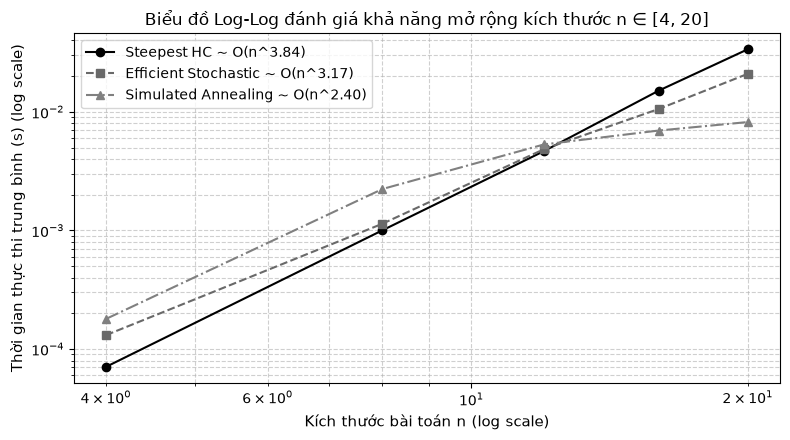

In [12]:
# Task 6: Problem Size Scalability Log-Log Plot
n_vals = [4, 8, 12, 16, 20]
t_steepest = []
t_eff = []
t_sa = []

for cur_n in n_vals:
    t_s_runs, t_e_runs, t_sa_runs = [], [], []
    for _ in range(25):
        b = random_board(cur_n)
        _, _, _, _, dur_s, _ = steepest_ascent_hc(b)
        _, _, _, _, dur_e, _ = efficient_stochastic_hc(b)
        _, _, _, _, dur_sa, _ = simulated_annealing(b, max_steps=1000)
        t_s_runs.append(dur_s)
        t_e_runs.append(dur_e)
        t_sa_runs.append(dur_sa)
    t_steepest.append(np.mean(t_s_runs))
    t_eff.append(np.mean(t_e_runs))
    t_sa.append(np.mean(t_sa_runs))

# Ước lượng độ phức tạp thực nghiệm (Slope của log-log regression)
log_n = np.log(n_vals)
slope_s, _ = np.polyfit(log_n, np.log(t_steepest), 1)
slope_e, _ = np.polyfit(log_n, np.log(t_eff), 1)
slope_sa, _ = np.polyfit(log_n, np.log(t_sa), 1)

print(f"Hệ số góc thực nghiệm (Empirical Big-O):")
print(f"- Steepest-ascent HC:    O(n^{slope_s:.2f})")
print(f"- Efficient Stochastic: O(n^{slope_e:.2f})")
print(f"- Simulated Annealing:  O(n^{slope_sa:.2f})")

plt.figure(figsize=(8, 4.5))
plt.loglog(n_vals, t_steepest, 'o-', label=f'Steepest HC ~ O(n^{slope_s:.2f})', color='black', linewidth=1.5)
plt.loglog(n_vals, t_eff, 's--', label=f'Efficient Stochastic ~ O(n^{slope_e:.2f})', color='dimgray', linewidth=1.5)
plt.loglog(n_vals, t_sa, '^-.', label=f'Simulated Annealing ~ O(n^{slope_sa:.2f})', color='gray', linewidth=1.5)
plt.xlabel('Kích thước bài toán n (log scale)', fontsize=11)
plt.ylabel('Thời gian thực thi trung bình (s) (log scale)', fontsize=11)
plt.title('Biểu đồ Log-Log đánh giá khả năng mở rộng kích thước n ∈ [4, 20]', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [13]:
# Advanced Task: Exploring other Local Moves Operators
# Cài đặt 4 toán tử di chuyển cục bộ:
def op_single_step(board):
    """Di chuyển một quân hậu lên hoặc xuống chỉ 1 ô (+1 hoặc -1)"""
    n = len(board)
    col = random.randint(0, n - 1)
    orig_row = board[col]
    delta = random.choice([-1, 1])
    new_row = orig_row + delta
    if 0 <= new_row < n:
        new_b = list(board)
        new_b[col] = new_row
        return new_b
    return None

def op_column_swap(board):
    """Tráo đổi vị trí hàng của hai quân hậu ở 2 cột ngẫu nhiên"""
    n = len(board)
    c1, c2 = random.sample(range(n), 2)
    new_b = list(board)
    new_b[c1], new_b[c2] = new_b[c2], new_b[c1]
    return new_b

def op_dual_queen(board):
    """Chọn đồng thời 2 quân hậu và thay đổi vị trí của cả hai"""
    n = len(board)
    c1, c2 = random.sample(range(n), 2)
    new_b = list(board)
    new_b[c1] = random.choice([r for r in range(n) if r != board[c1]])
    new_b[c2] = random.choice([r for r in range(n) if r != board[c2]])
    return new_b

def op_adaptive(board):
    """Toán tử thích nghi: Ưu tiên di chuyển các quân hậu đang bị xung đột nhiều nhất"""
    n = len(board)
    col_conflicts = [0] * n
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                col_conflicts[i] += 1
                col_conflicts[j] += 1
    max_c = max(col_conflicts)
    if max_c > 0 and random.random() < 0.7:
        worst_cols = [c for c, count in enumerate(col_conflicts) if count == max_c]
        col = random.choice(worst_cols)
        new_b = list(board)
        new_b[col] = random.choice([r for r in range(n) if r != board[col]])
        return new_b
    else:
        return op_column_swap(board)

def run_hc_operator(board, op_fn, max_no_improve=None):
    t0 = time.perf_counter()
    n = len(board)
    if max_no_improve is None:
        max_no_improve = max(50, 4 * n * (n - 1))
    current = list(board)
    curr_h = conflicts(current)
    steps = 0
    history = [curr_h]
    no_improve = 0
    while curr_h > 0 and no_improve < max_no_improve:
        neighbor = op_fn(current)
        if neighbor is None:
            no_improve += 1
            continue
        h = conflicts(neighbor)
        if h < curr_h:
            current = neighbor
            curr_h = h
            steps += 1
            history.append(curr_h)
            no_improve = 0
        else:
            no_improve += 1
    t1 = time.perf_counter()
    return current, curr_h, steps, (t1 - t0), history

# Thực nghiệm 100 lần chạy trên 8-Queens và 12-Queens cho mỗi toán tử
ops = [
    ('Single-step', op_single_step),
    ('Column swap', op_column_swap),
    ('Dual-queen', op_dual_queen),
    ('Adaptive move', op_adaptive)
]

for test_n in [8, 12]:
    print(f"\n--- KẾT QUẢ THỰC NGHIỆM TRÊN {test_n}-QUEENS (100 LƯỢT) ---")
    for op_name, op_fn in ops:
        h_list = []
        times = []
        succ_times = []
        for _ in range(100):
            b = random_board(test_n)
            _, h_fin, _, dur, _ = run_hc_operator(b, op_fn)
            h_list.append(h_fin)
            times.append(dur)
            if h_fin == 0:
                succ_times.append(dur)
        succ_rate = (len(succ_times) / 100) * 100
        avg_succ_t = f"{np.mean(succ_times)*1000:.2f} ms" if succ_times else "N/A"
        print(f"[{op_name:12s}] Tỷ lệ thành công = {succ_rate:5.1f}%, Xung đột TB = {np.mean(h_list):.2f}, Thời gian giải thành công = {avg_succ_t}")


--- KẾT QUẢ THỰC NGHIỆM TRÊN 8-QUEENS (100 LƯỢT) ---
[Single-step ] Tỷ lệ thành công =   0.0%, Xung đột TB = 3.60, Thời gian giải thành công = N/A
[Column swap ] Tỷ lệ thành công =   0.0%, Xung đột TB = 4.57, Thời gian giải thành công = N/A
[Dual-queen  ] Tỷ lệ thành công =   5.0%, Xung đột TB = 1.46, Thời gian giải thành công = 0.65 ms
[Adaptive move] Tỷ lệ thành công =  13.0%, Xung đột TB = 1.22, Thời gian giải thành công = 0.86 ms

--- KẾT QUẢ THỰC NGHIỆM TRÊN 12-QUEENS (100 LƯỢT) ---


[Single-step ] Tỷ lệ thành công =   0.0%, Xung đột TB = 5.66, Thời gian giải thành công = N/A
[Column swap ] Tỷ lệ thành công =   0.0%, Xung đột TB = 6.52, Thời gian giải thành công = N/A


[Dual-queen  ] Tỷ lệ thành công =   0.0%, Xung đột TB = 1.99, Thời gian giải thành công = N/A


[Adaptive move] Tỷ lệ thành công =  11.0%, Xung đột TB = 1.45, Thời gian giải thành công = 2.81 ms


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# More Things to Do: Min-Conflicts Heuristic cho bài toán N-Queens quy mô lớn (n = 50)
def min_conflicts_nqueens(n, max_steps=1000):
    """
    Min-Conflicts cho N-Queens:
    Khởi tạo bàn cờ ngẫu nhiên kích thước n.
    Tại mỗi bước, chọn ngẫu nhiên quân hậu bị xung đột và dời vào hàng có ít xung đột nhất (min-conflicts).
    Thuật toán giải N-Queens quy mô n = 20, 30 rất nhanh chóng.
    """
    t0 = time.perf_counter()
    board = list(np.random.randint(0, n, size=n))
    for step in range(max_steps):
        curr_h = conflicts(board)
        if curr_h == 0:
            t1 = time.perf_counter()
            return board, 0, step, (t1 - t0), True
            
        conflicted_cols = []
        for i in range(n):
            for j in range(i + 1, n):
                if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                    if i not in conflicted_cols: conflicted_cols.append(i)
                    if j not in conflicted_cols: conflicted_cols.append(j)
                    
        col = random.choice(conflicted_cols)
        orig_row = board[col]
        row_conflicts = []
        for row in range(n):
            board[col] = row
            row_conflicts.append(conflicts(board))
        board[col] = orig_row
        min_c = min(row_conflicts)
        best_rows = [r for r, c in enumerate(row_conflicts) if c == min_c]
        board[col] = random.choice(best_rows)
        
    t1 = time.perf_counter()
    return board, conflicts(board), max_steps, (t1 - t0), False

print("Thử nghiệm Min-Conflicts N-Queens trên n = 20...")
b_large, h_large, steps_large, t_large, ok_large = min_conflicts_nqueens(20, max_steps=500)
print(f"Kết quả: Thành công = {ok_large}, Xung đột = {h_large}, Số bước = {steps_large}, Thời gian = {t_large*1000:.2f} ms")

Thử nghiệm Min-Conflicts N-Queens trên n = 20...
Kết quả: Thành công = True, Xung đột = 0, Số bước = 177, Thời gian = 32.38 ms
